<a href="https://colab.research.google.com/github/Angelinat3/IP-CV_odd-Angelina-Thennessa-Jo-3/blob/main/Pertemuan5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ===== SEL IDENTITAS - JANGAN DIHAPUS, HARUS SEL PERTAMA =====
import sys, platform, hashlib, datetime, zoneinfo
NAMA = 'Angelina Thennesssa Jo'
NIM = '2107020076' # ganti dengan NIM Anda
N = int(NIM[-3:])
PARAM = {
 'bins' : 2 ** ((N % 4) + 3),
 'clip' : round(1.0 + (N % 5) * 0.5, 1),
 'tile' : (N % 4) + 2,
 'L' : 2 ** ((N % 3) + 1),
}
waktu = datetime.datetime.now(zoneinfo.ZoneInfo('Asia/Jakarta'))
print('NAMA :', NAMA)
print('NIM :', NIM, '| N =', N)
for k, v in PARAM.items():
 print('%-6s :' % k, v)
print('WAKTU :', waktu.strftime('%Y-%m-%d %H:%M:%S %Z'))
print('SISTEM :', sys.version.split()[0], platform.platform())
kunci = NIM + '|' + waktu.strftime('%Y-%m-%d')
print('TOKEN :', hashlib.sha256(kunci.encode()).hexdigest()[:16])

NAMA : Angelina Thennesssa Jo
NIM : 2107020076 | N = 76
bins   : 8
clip   : 1.5
tile   : 2
L      : 4
WAKTU : 2026-10-22 08:57:37 WIB
SISTEM : 3.13.16 Linux-6.6.122+-x86_64-with-glibc2.39
TOKEN : 8753d6707c9fbc5c


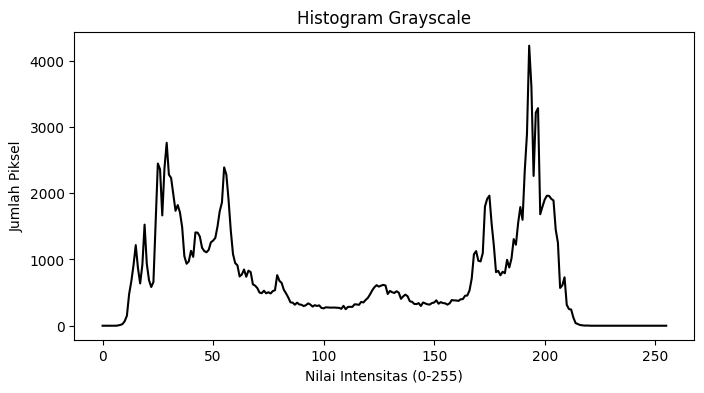

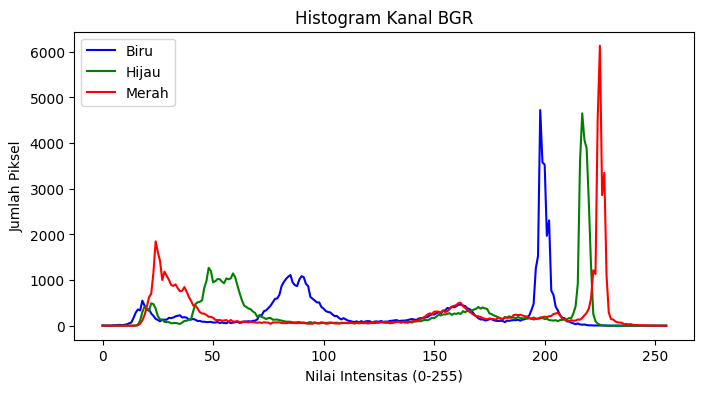

In [ ]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

BASE = "/content/drive/MyDrive/PCVK/Images/"

def histogram_manual(img, L=256):
    h = np.zeros(L, dtype=np.int64)
    for y in range(img.shape[0]):
        for x in range(img.shape[1]):
            h[img[y, x]] += 1
    return h

# 1. Grayscale Image Processing
gray = cv.imread(BASE + 'tilKTM1b.jpg', cv.IMREAD_GRAYSCALE)

if gray is None:
    raise FileNotFoundError(f"File not found at: {BASE + 'tilKTM1b.jpg'}")

h = histogram_manual(gray)
p = h / gray.size
cdf = np.cumsum(p)
assert h.sum() == gray.size

plt.figure(figsize=(8, 4))
plt.title("Histogram Grayscale")
plt.plot(h, color='black')
plt.xlabel("Nilai Intensitas (0-255)")
plt.ylabel("Jumlah Piksel")
plt.show()

# 2. BGR (Color) Image Processing
bgr = cv.imread(BASE + 'KTM1d.jpg')
if bgr is None:
    raise FileNotFoundError(f"File not found at: {BASE + 'KTM1d.jpg'}")

plt.figure(figsize=(8, 4))
plt.title("Histogram Kanal BGR")
warna = ['b', 'g', 'r']
for i, nama in enumerate(['Biru', 'Hijau', 'Merah']):
    plt.plot(histogram_manual(bgr[:, :, i]), label=nama, color=warna[i])

plt.xlabel("Nilai Intensitas (0-255)")
plt.ylabel("Jumlah Piksel")
plt.legend()
plt.show()

In [ ]:
def floyd_steinberg(gray, L=2):
  img = gray.astype(np.float32).copy()
  step = 255.0/(L-1)
  H, W = img.shape
  for y in range(H):
    for x in range(W):
      lama =img[y, x]
      baru = np.round(lama/step) * step
      img[y,x] = baru
      error = lama - baru
      if x + 1 < W: img[y, x+1] += error * 7 / 16
      if x > 0 and y+1 < H: img[y+1, x-1] += error * 3 / 16
      if y + 1 < H: img[y+1, x ] += error * 5 / 16
      if x + 1 < W and y+1 < H: img[y+1, x+1] += error * 1 / 16
  return np.clip(img, 0, 255).astype(np.uint8)

Praktikum

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import cv2 as cv
from google.colab.patches import cv2_imshow
from skimage import io
import matplotlib.pyplot as plt
import numpy as np
import math
import os
import glob

<BarContainer object of 256 artists>

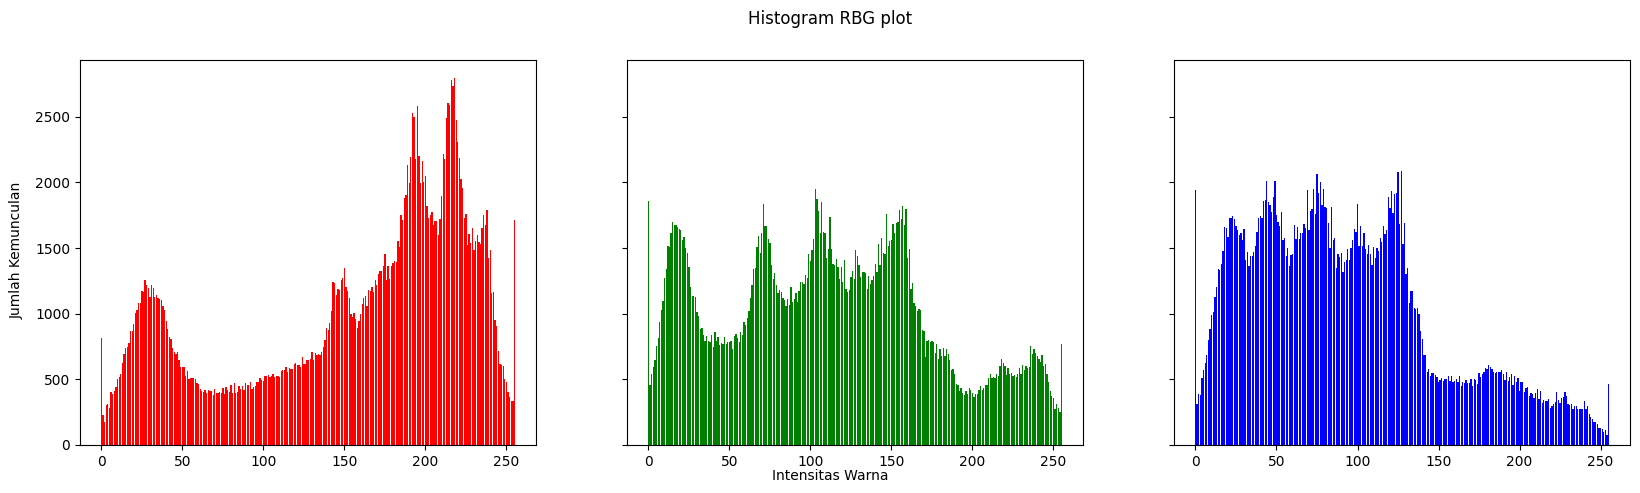

In [ ]:
img = cv.imread('/content/drive/MyDrive/PCVK/Images/lena.jpg')
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

height, width, depth = np.shape(img)
names = np.arange(256)

red   = [0]*256
green = [0]*256
blue  = [0]*256

for y in range(0, height) :
  for x in range(0, width) :
    red[img[y][x][0]] += 1
    green[img[y][x][1]] += 1
    blue[img[y][x][2]] += 1

names = np.arange(256)
fig, axs = plt.subplots(1, 3, figsize=[20,5], sharex= True, sharey= True)
fig.suptitle('Histogram RBG plot')
fig.text(0.09, 0.5, 'Jumlah Kemunculan', va= 'center', rotation= 'vertical')
fig.text(0.5, 0.04, 'Intensitas Warna', ha='center')
axs[0].bar(names, red, color= 'red')
axs[1].bar(names, green, color= 'green')
axs[2].bar(names, blue, color= 'blue')

=== NOMOR 1: UJI SELISIH HISTOGRAM ===
Selisih Maksimum untuk lena.jpg: 0
Error: Gambar pada '/content/drive/MyDrive/PCVK/Images/KTM1b.jpg' tidak ditemukan!
--------------------------------------------------
Error: Gambar /content/drive/MyDrive/PCVK/Images/KTM1b.jpg tidak ditemukan!


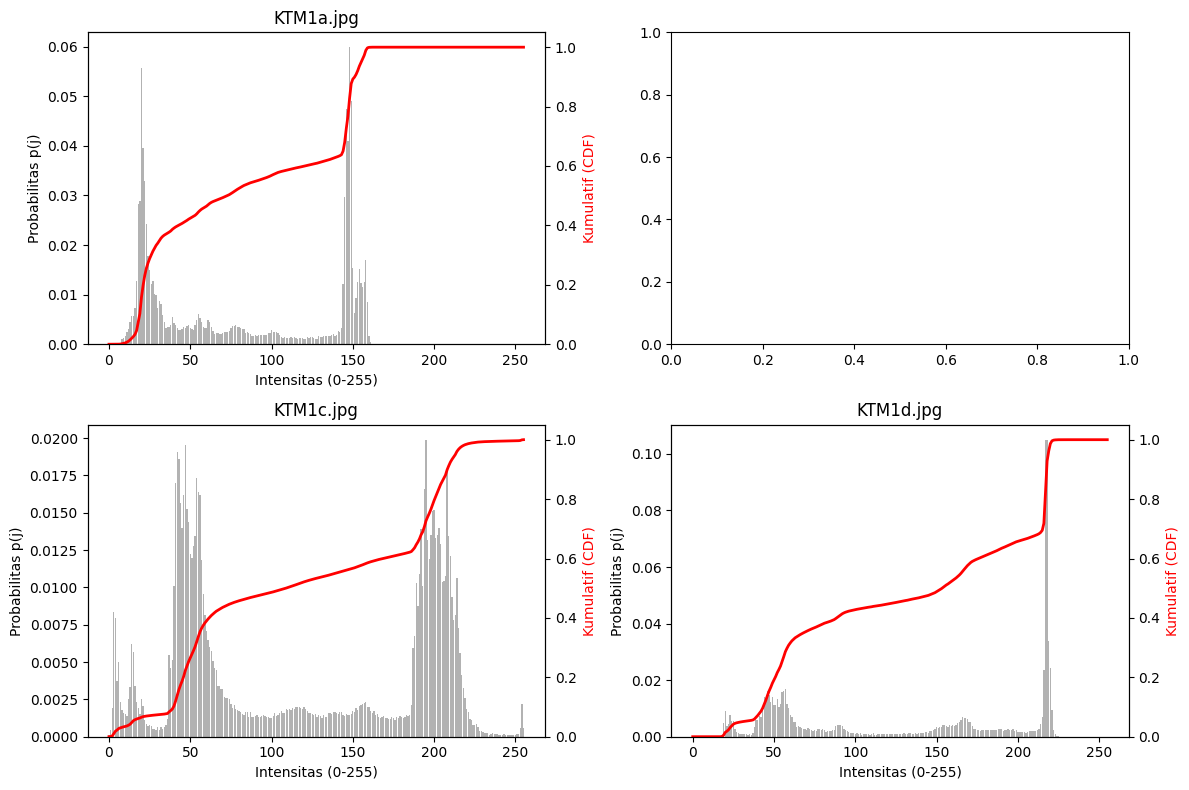

In [ ]:
# Fungsi histogram manual
def histogram_manual(img, L=256):
    h = np.zeros(L, dtype=np.int64)
    for y in range(img.shape[0]):
        for x in range(img.shape[1]):
            h[img[y, x]] += 1
    return h

# Tentukan path folder dan file (Sesuaikan dengan nama folder di Google Drive kamu)
CONTOH = '/content/drive/MyDrive/PCVK/Images'  # Folder tempat lena.jpg
BASE   = '/content/drive/MyDrive/PCVK/Images'  # Folder tempat foto KTM1a - KTM1d

file_lena = CONTOH + '/lena.jpg'
file_ktm  = BASE + '/KTM1b.jpg'

# Nilai PARAM (Sesuaikan jika ada ketentuan dari modul/dosen)
PARAM = {'bins': 16}

print("=== NOMOR 1: UJI SELISIH HISTOGRAM ===")
for path in [file_lena, file_ktm]:
    img = cv.imread(path, cv.IMREAD_GRAYSCALE)
    if img is None:
        print(f"Error: Gambar pada '{path}' tidak ditemukan!")
        continue

    h_manual = histogram_manual(img)
    h_np, _  = np.histogram(img.ravel(), 256, [0, 256])
    h_cv     = cv.calcHist([img], [0], None, [256], [0, 256]).flatten().astype(np.int64)

    diff_manual_np = np.max(np.abs(h_manual - h_np))
    diff_manual_cv = np.max(np.abs(h_manual - h_cv))
    diff = max(diff_manual_np, diff_manual_cv)

    nama_file = path.split('/')[-1]
    print(f"Selisih Maksimum untuk {nama_file}: {diff}") # Harus 0
print("-" * 50)


fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for idx, char in enumerate(['a', 'b', 'c', 'd']):
    file_path = f"{BASE}/KTM1{char}.jpg"
    img = cv.imread(file_path, cv.IMREAD_GRAYSCALE)
    if img is None:
        print(f"Error: Gambar {file_path} tidak ditemukan!")
        continue

    h = cv.calcHist([img], [0], None, [256], [0, 256]).flatten()
    p = h / img.size
    cdf = np.cumsum(p)

    ax1 = axes.ravel()[idx]
    ax2 = ax1.twinx()

    ax1.bar(range(256), p, color='gray', alpha=0.6, label='PDF p(j)')
    ax2.plot(cdf, color='red', linewidth=2, label='CDF')

    ax1.set_title(f"KTM1{char}.jpg")
    ax1.set_xlabel("Intensitas (0-255)")
    ax1.set_ylabel("Probabilitas p(j)")
    ax2.set_ylabel("Kumulatif (CDF)", color='red')
    ax2.set_ylim([0, 1.05])

plt.tight_layout()
plt.show()


img_ktm1b = cv.imread(file_ktm, cv.IMREAD_GRAYSCALE)

if img_ktm1b is not None:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    # 256 Bins
    ax1.hist(img_ktm1b.ravel(), 256, [0, 256], color='blue')
    ax1.set_title("Histogram (256 Bins)")
    ax1.set_xlabel("Bin Intensitas")
    ax1.set_ylabel("Jumlah Piksel")

    # PARAM['bins'] Bins (misal 16 Bins)
    bins_custom = PARAM['bins']
    ax2.hist(img_ktm1b.ravel(), bins_custom, [0, 256], color='orange', edgecolor='black')

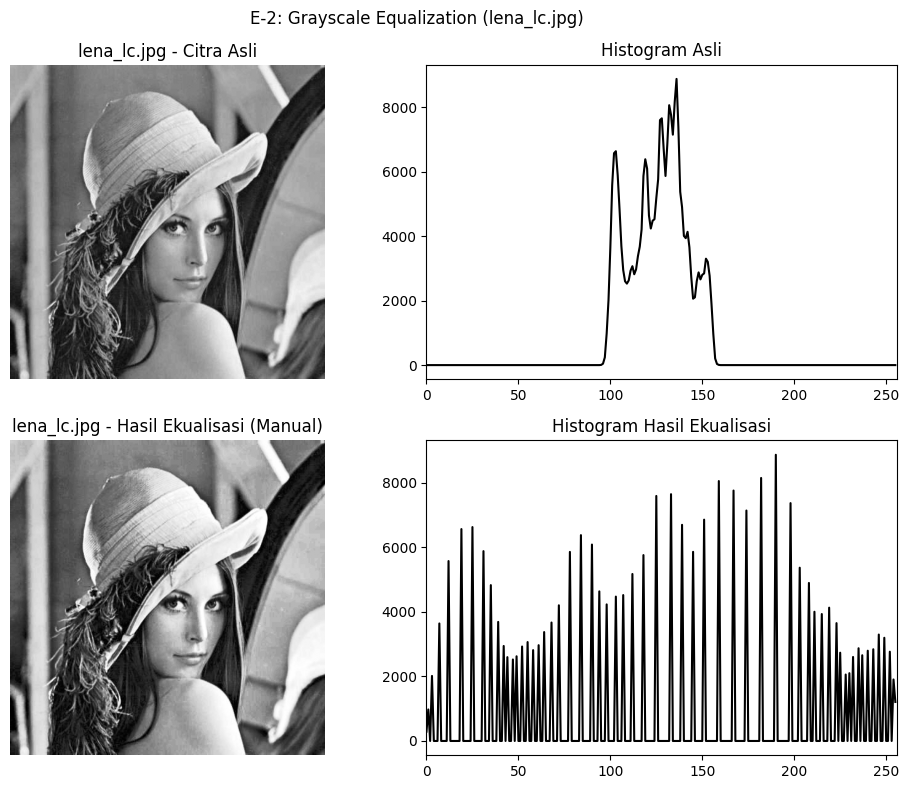

=== HASIL UJI SELISIH lena_lc.jpg ===
Selisih Maksimum (Manual vs cv.equalizeHist): 0
------------------------------------------------------------


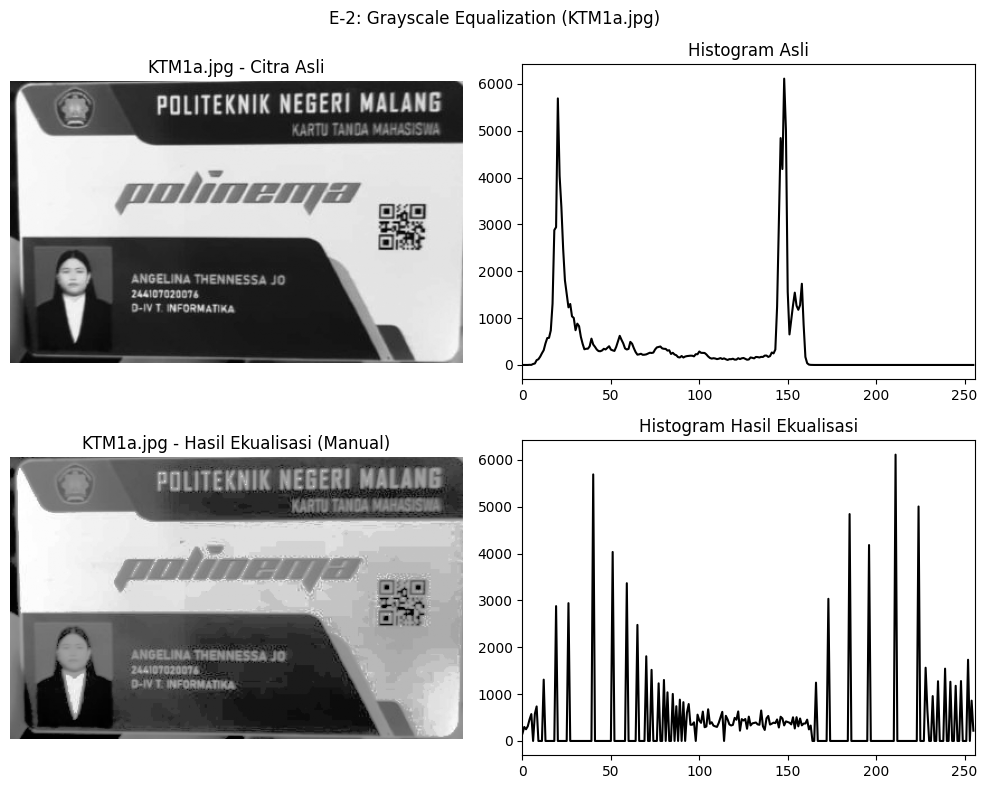

=== HASIL UJI SELISIH KTM1a.jpg ===
Selisih Maksimum (Manual vs cv.equalizeHist): 1
------------------------------------------------------------


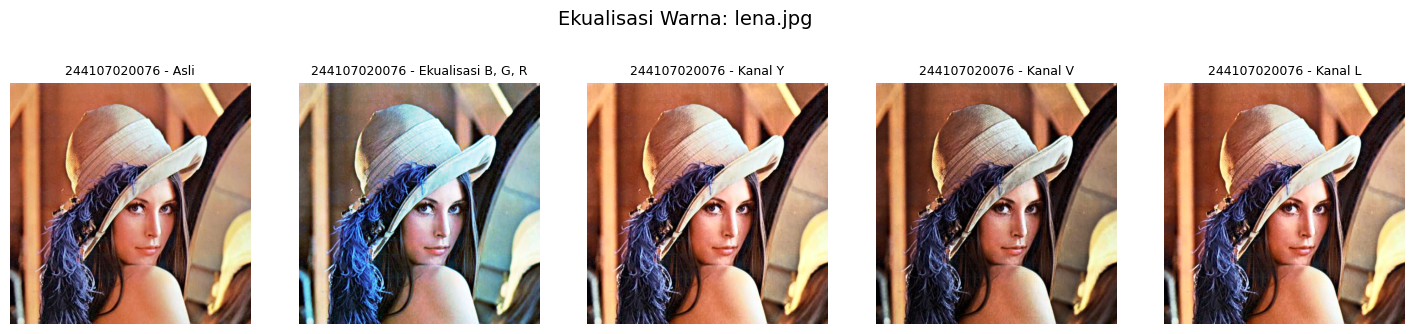


=== TABEL HASIL EKUALISASI WARNA (lena.jpg) ===
Cara Ekualisasi           geser Hue (der)  rerata terang sesudah
-----------------------------------------------------------------
Asli                                 0.00                  122.2
Ekualisasi B, G, R                  53.03                  127.4
Kanal Y                              0.40                  127.9
Kanal V                              0.87                  100.6
Kanal L                              1.65                  122.7
-----------------------------------------------------------------

=== JAWABAN NO 4: PERBANDINGAN EQUALIZEHIST VS CLAHE (Kanal Y) ===
Kanal Y (EqualizeHist)               0.40                  127.9
Kanal Y (CLAHE)                      0.38                  130.9
-----------------------------------------------------------------


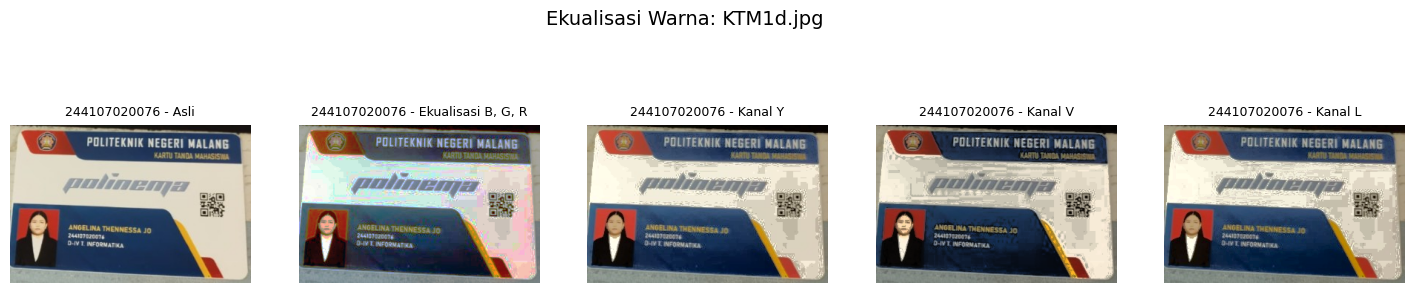


=== TABEL HASIL EKUALISASI WARNA (KTM1d.jpg) ===
Cara Ekualisasi           geser Hue (der)  rerata terang sesudah
-----------------------------------------------------------------
Asli                                 0.00                  134.3
Ekualisasi B, G, R                  50.65                  130.3
Kanal Y                              0.48                  131.2
Kanal V                              1.65                  115.7
Kanal L                              2.68                  124.9
-----------------------------------------------------------------

=== JAWABAN NO 4: PERBANDINGAN EQUALIZEHIST VS CLAHE (Kanal Y) ===
Kanal Y (EqualizeHist)               0.48                  131.2
Kanal Y (CLAHE)                      0.02                  138.9
-----------------------------------------------------------------


In [ ]:
CONTOH = '/content/drive/MyDrive/PCVK/Images'  # Folder tempat lena.jpg / lena_lc.jpg
BASE   = '/content/drive/MyDrive/PCVK/Images'  # Folder tempat foto KTM1a.jpg / KTM1d.jpg
NIM    = '244107020076'                       # Ganti dengan NIM kamu

PARAM = {
    'clip': 2.0,
    'tile': 8
}

file_lena_lc = CONTOH + '/lena_lc.jpg'
file_ktm1a   = BASE + '/KTM1a.jpg'
file_lena    = CONTOH + '/lena.jpg'
file_ktm1d   = BASE + '/KTM1d.jpg'

def histogram_equalization_manual(img, L=256):
    # 1. Menghitung frekuensi kemunculan piksel
    h = np.zeros(L, dtype=np.int64)
    for y in range(img.shape[0]):
        for x in range(img.shape[1]):
            h[img[y, x]] += 1

    # 2. Penjumlahan kumulatif (CDF) & normalisasi
    pdf = h / img.size
    cdf = np.cumsum(pdf)

    # 3. Implementasi rumus K0 (skala warna baru)
    s = np.round((L - 1) * cdf).astype(np.uint8)

    # 4. Transformasi kembali dalam bentuk citra
    img_equalized = s[img]
    return img_equalized, h


def ekualisasi_grayscale_dan_uji(filepath, nama_label):
    img = cv.imread(filepath, cv.IMREAD_GRAYSCALE)
    if img is None:
        print(f"Error: Gambar '{filepath}' tidak ditemukan!")
        return

    # 1. Manual Implementation
    img_manual, h_asli = histogram_equalization_manual(img)

    # 2. CV2 equalizeHist (Potongan kode Langkah 2)
    img_cv = cv.equalizeHist(img)

    # Selisih maksimum
    selisih_maks = np.max(np.abs(img_manual.astype(np.int16) - img_cv.astype(np.int16)))

    # Plot Tampilan Citra dan Histogram Sebelum & Sesudah
    fig, axes = plt.subplots(2, 2, figsize=(10, 8))
    axes[0, 0].imshow(img, cmap='gray')
    axes[0, 0].set_title(f"{nama_label} - Citra Asli")
    axes[0, 0].axis('off')

    axes[0, 1].plot(h_asli, color='black')
    axes[0, 1].set_title("Histogram Asli")
    axes[0, 1].set_xlim([0, 256])

    axes[1, 0].imshow(img_manual, cmap='gray')
    axes[1, 0].set_title(f"{nama_label} - Hasil Ekualisasi (Manual)")
    axes[1, 0].axis('off')

    h_manual = cv.calcHist([img_manual], [0], None, [256], [0, 256]).flatten()
    axes[1, 1].plot(h_manual, color='black')
    axes[1, 1].set_title("Histogram Hasil Ekualisasi")
    axes[1, 1].set_xlim([0, 256])

    plt.suptitle(f"E-2: Grayscale Equalization ({nama_label})", fontsize=12)
    plt.tight_layout()
    plt.show()

    print(f"=== HASIL UJI SELISIH {nama_label} ===")
    print(f"Selisih Maksimum (Manual vs cv.equalizeHist): {selisih_maks}")
    print("-" * 60)

# Uji Tahap 1: lena_lc.jpg | Tahap 2: KTM1a.jpg
ekualisasi_grayscale_dan_uji(file_lena_lc, "lena_lc.jpg")
ekualisasi_grayscale_dan_uji(file_ktm1a, "KTM1a.jpg")


def geser_hue(asli, hasil):
    h1 = cv.cvtColor(asli, cv.COLOR_BGR2HSV)[:, :, 0].astype(np.int16)
    h2 = cv.cvtColor(hasil, cv.COLOR_BGR2HSV)[:, :, 0].astype(np.int16)
    d  = np.abs(h1 - h2)
    d  = np.minimum(d, 180 - d) # Hue melingkar 0-179
    return d.mean()


def ekualisasi_warna_lengkap(filepath, nama_label):
    bgr = cv.imread(filepath)
    if bgr is None:
        print(f"Error: Gambar '{filepath}' tidak ditemukan!")
        return

    # Cara 1: Ekualisasi kanal B, G, R terpisah (Langkah 3 & Potongan Gambar 2)
    b, g, r = cv.split(bgr)
    b_equalized = cv.equalizeHist(b)
    g_equalized = cv.equalizeHist(g)
    r_equalized = cv.equalizeHist(r)
    he_rgb = cv.merge([b_equalized, g_equalized, r_equalized])

    # Cara 2: Kanal Terang Y (YCrCb)
    ycrcb = cv.cvtColor(bgr, cv.COLOR_BGR2YCrCb)
    y, cr, cb = cv.split(ycrcb)
    he_y = cv.cvtColor(cv.merge([cv.equalizeHist(y), cr, cb]), cv.COLOR_YCrCb2BGR)

    # Varian 2a: Kanal Terang V (HSV)
    hsv = cv.cvtColor(bgr, cv.COLOR_BGR2HSV)
    h, sat, v = cv.split(hsv)
    he_v = cv.cvtColor(cv.merge([h, sat, cv.equalizeHist(v)]), cv.COLOR_HSV2BGR)

    # Varian 2b: Kanal Terang L (LAB)
    lab = cv.cvtColor(bgr, cv.COLOR_BGR2LAB)
    l, a, b_lab = cv.split(lab)
    he_l = cv.cvtColor(cv.merge([cv.equalizeHist(l), a, b_lab]), cv.COLOR_LAB2BGR)

    # Tampilkan 5 Citra Berdampingan
    judul = ['Asli', 'Ekualisasi B, G, R', 'Kanal Y', 'Kanal V', 'Kanal L']
    citra = [bgr, he_rgb, he_y, he_v, he_l]

    plt.figure(figsize=(18, 4))
    for i, (c, t) in enumerate(zip(citra, judul), 1):
        plt.subplot(1, 5, i)
        plt.imshow(cv.cvtColor(c, cv.COLOR_BGR2RGB))
        plt.title(f"{NIM} - {t}", fontsize=9)
        plt.axis('off')
    plt.suptitle(f"Ekualisasi Warna: {nama_label}", fontsize=14)
    plt.show()

    # Cetak Tabel Pergeseran Hue dan Rerata Kecerahan
    print(f"\n=== TABEL HASIL EKUALISASI WARNA ({nama_label}) ===")
    print('%-22s %18s %22s' % ('Cara Ekualisasi', 'geser Hue (der)', 'rerata terang sesudah'))
    print("-" * 65)
    for t, c in zip(judul, citra):
        r_hue = geser_hue(bgr, c) * 2
        r_terang = cv.cvtColor(c, cv.COLOR_BGR2GRAY).mean()
        print('%-22s %18.2f %22.1f' % (t, r_hue, r_terang))
    print("-" * 65)

    # --- PERTANYAAN 4: Variasi CLAHE pada Kanal Terang (Kanal Y - YCrCb) ---
    clahe = cv.createCLAHE(clipLimit=PARAM['clip'], tileGridSize=(PARAM['tile'], PARAM['tile']))
    he_y_clahe = cv.cvtColor(cv.merge([clahe.apply(y), cr, cb]), cv.COLOR_YCrCb2BGR)

    print(f"\n=== JAWABAN NO 4: PERBANDINGAN EQUALIZEHIST VS CLAHE (Kanal Y) ===")
    print('%-22s %18.2f %22.1f' % ('Kanal Y (EqualizeHist)', geser_hue(bgr, he_y) * 2, cv.cvtColor(he_y, cv.COLOR_BGR2GRAY).mean()))
    print('%-22s %18.2f %22.1f' % ('Kanal Y (CLAHE)', geser_hue(bgr, he_y_clahe) * 2, cv.cvtColor(he_y_clahe, cv.COLOR_BGR2GRAY).mean()))
    print("-" * 65)

# Uji Tahap 1: lena.jpg | Tahap 2: KTM1d.jpg
ekualisasi_warna_lengkap(file_lena, "lena.jpg")
ekualisasi_warna_lengkap(file_ktm1d, "KTM1d.jpg")

1. Cara dengan pergeseran Hue paling besar:
Ekualisasi B, G, R terpisah (Ekualisasi kanal B,  G, R).

2. Mengapa ekualisasi kanal terang tetap menghasilkan pergeseran Hue tidak nol?
Ketika citra yang telah diekualisasi pada ruang warna lain (YCrCb/HSV/LAB) dikonversi kembali ke ruang warna BGR, terjadi pembulatan angka (rounding) dan pemotongan nilai (clipping rentang 0–255).

3. Perubahan presisi desimal saat transformasi matematis antar-ruang warna inilah yang menyebabkan nilai Hue sedikit bergeser meski kanal warna aslinya tidak diubah.

Pilihan kanal terbaik (Y, V, atau L) untuk KTM1d.jpg:
Umumnya Kanal Y (YCrCb) atau Kanal L (LAB).

4. Perbandingan CLAHE vs Ekualisasi Biasa:

CLAHE menghasilkan pergeseran Hue yang lebih kecil dan rerata kecerahan yang lebih natural. CLAHE membatasi peningkatan kontras berlebih (clip limit) pada blok lokal sehingga noise tidak meledak dan warna kartu KTM tetap alami.

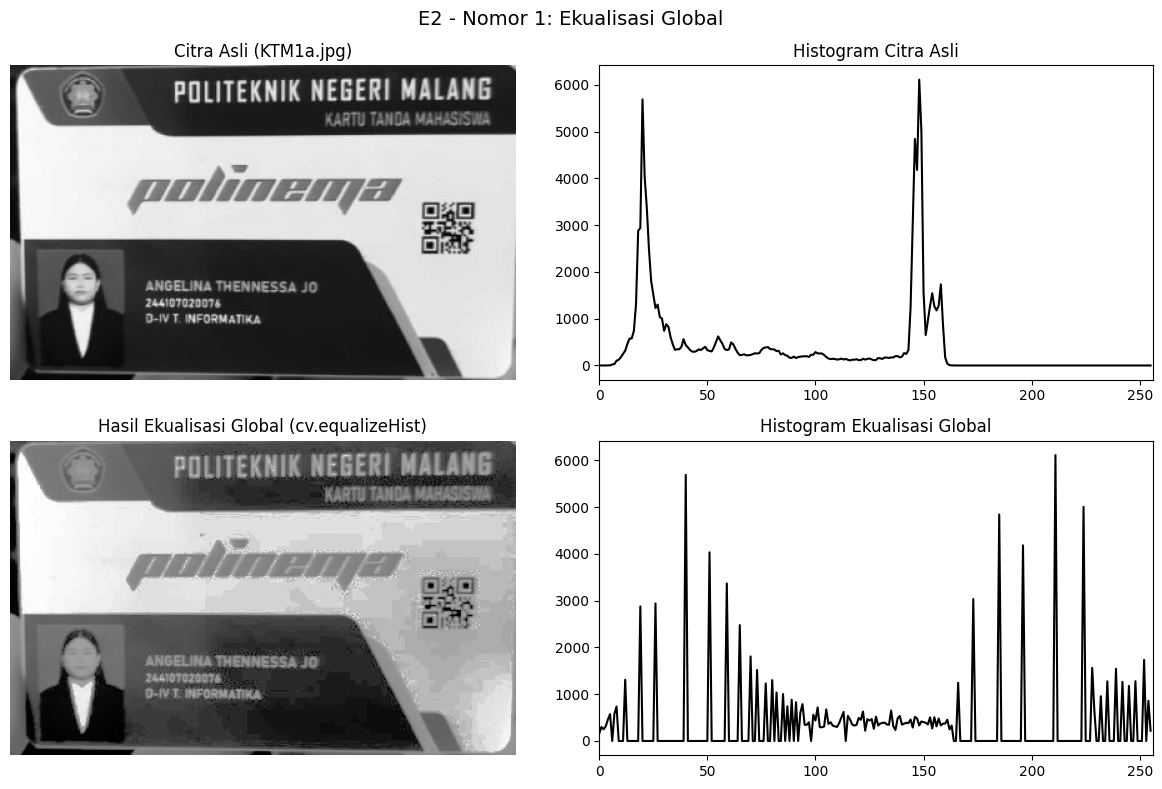

=== HASIL NOMOR 1 ===
Nilai PSNR (Asli vs Ekualisasi Global): 13.64 dB



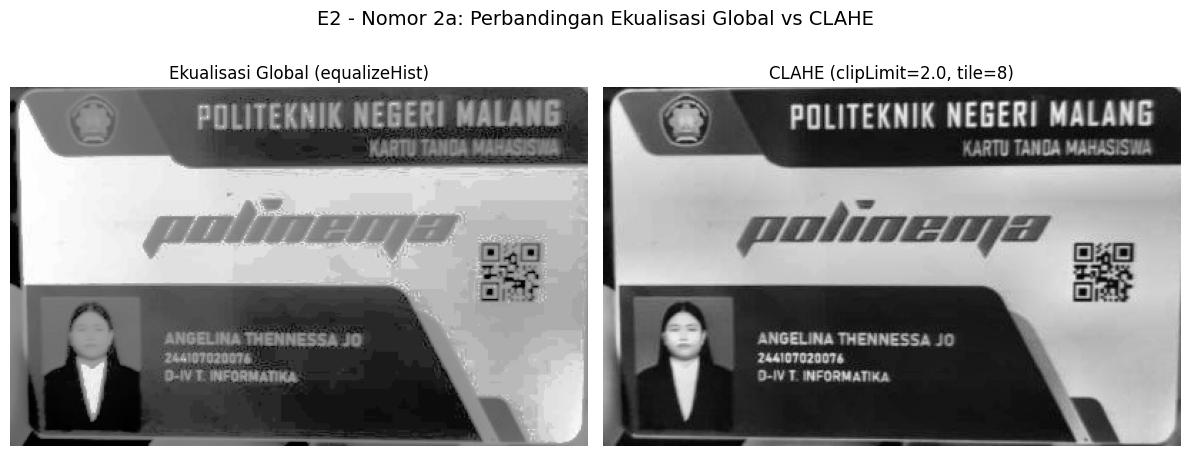

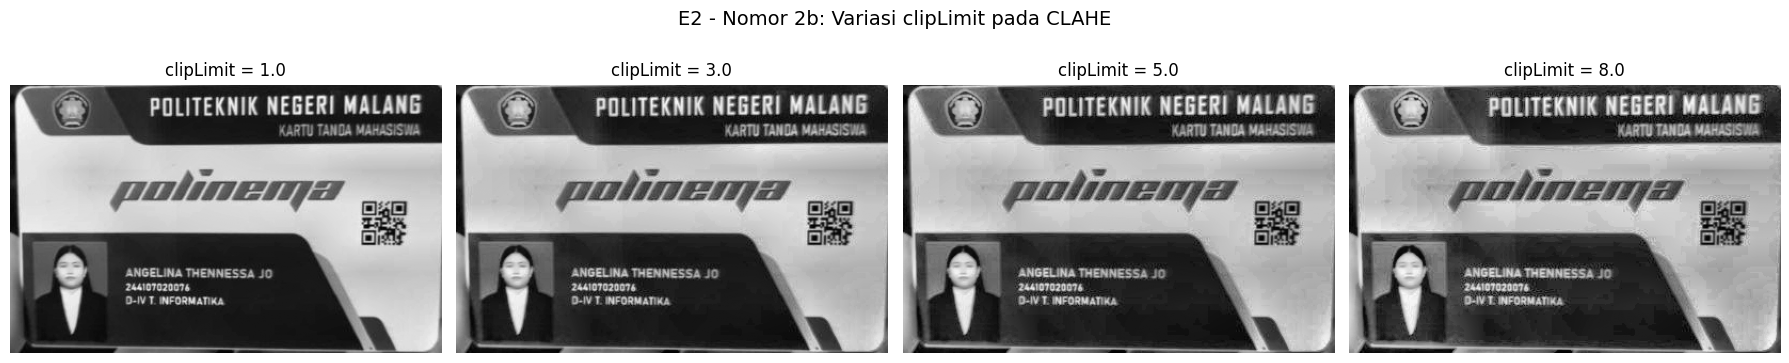

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

BASE = '/content/drive/MyDrive/PCVK/Images' # Path folder foto KTM Anda
file_ktm1a = BASE + '/KTM1a.jpg'

PARAM = {
    'clip': 2.0,
    'tile': 8
}

# Fungsi Ekualisasi Manual
def histogram_equalization_manual(img, L=256):
    h = np.zeros(L, dtype=np.int64)
    for y in range(img.shape[0]):
        for x in range(img.shape[1]):
            h[img[y, x]] += 1
    pdf = h / img.size
    cdf = np.cumsum(pdf)
    s = np.round((L - 1) * cdf).astype(np.uint8)
    return s[img]

# Baca gambar KTM1a.jpg versi grayscale
img_asli = cv.imread(file_ktm1a, cv.IMREAD_GRAYSCALE)

if img_asli is None:
    print(f"Error: Gambar '{file_ktm1a}' tidak ditemukan! Periksa path folder Anda.")
else:
    # a. Terapkan Ekualisasi Manual dan cv.equalizeHist
    img_manual = histogram_equalization_manual(img_asli)
    img_global = cv.equalizeHist(img_asli)

    # b. Layout Tampilan Citra Asli, Hasil Ekualisasi, dan Histogramnya
    h_asli = cv.calcHist([img_asli], [0], None, [256], [0, 256]).flatten()
    h_global = cv.calcHist([img_global], [0], None, [256], [0, 256]).flatten()

    fig, axes = plt.subplots(2, 2, figsize=(12, 8))

    # Baris 1: Asli
    axes[0, 0].imshow(img_asli, cmap='gray')
    axes[0, 0].set_title("Citra Asli (KTM1a.jpg)")
    axes[0, 0].axis('off')

    axes[0, 1].plot(h_asli, color='black')
    axes[0, 1].set_title("Histogram Citra Asli")
    axes[0, 1].set_xlim([0, 256])

    # Baris 2: Ekualisasi Global
    axes[1, 0].imshow(img_global, cmap='gray')
    axes[1, 0].set_title("Hasil Ekualisasi Global (cv.equalizeHist)")
    axes[1, 0].axis('off')

    axes[1, 1].plot(h_global, color='black')
    axes[1, 1].set_title("Histogram Ekualisasi Global")
    axes[1, 1].set_xlim([0, 256])

    plt.suptitle("E2 - Nomor 1: Ekualisasi Global", fontsize=14)
    plt.tight_layout()
    plt.show()

    # c. Hitung PSNR antara Citra Asli dan Hasil Ekualisasi Global
    psnr_global = cv.PSNR(img_asli, img_global)
    print(f"=== HASIL NOMOR 1 ===")
    print(f"Nilai PSNR (Asli vs Ekualisasi Global): {psnr_global:.2f} dB\n")

    # a. Penerapan CLAHE sesuai PARAM['clip'] dan PARAM['tile']
    clip_base = PARAM['clip']
    tile_base = PARAM['tile']

    clahe_default = cv.createCLAHE(clipLimit=clip_base, tileGridSize=(tile_base, tile_base))
    img_clahe_default = clahe_default.apply(img_asli)

    # Perbandingan Global vs CLAHE Default
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].imshow(img_global, cmap='gray')
    axes[0].set_title("Ekualisasi Global (equalizeHist)")
    axes[0].axis('off')

    axes[1].imshow(img_clahe_default, cmap='gray')
    axes[1].set_title(f"CLAHE (clipLimit={clip_base}, tile={tile_base})")
    axes[1].axis('off')

    plt.suptitle("E2 - Nomor 2a: Perbandingan Ekualisasi Global vs CLAHE", fontsize=14)
    plt.tight_layout()
    plt.show()

    # b. Mencoba Tiga Nilai clipLimit Lain di Sekitar PARAM['clip']
    clip_values = [1.0, 3.0, 5.0, 8.0]

    fig, axes = plt.subplots(1, 4, figsize=(18, 4))
    for i, clip in enumerate(clip_values):
        clahe_variasi = cv.createCLAHE(clipLimit=clip, tileGridSize=(tile_base, tile_base))
        img_clahe_var = clahe_variasi.apply(img_asli)

        axes[i].imshow(img_clahe_var, cmap='gray')
        axes[i].set_title(f"clipLimit = {clip}")
        axes[i].axis('off')

    plt.suptitle("E2 - Nomor 2b: Variasi clipLimit pada CLAHE", fontsize=14)
    plt.tight_layout()
    plt.show()

### **Jawaban Laporan Analisis (E2)**

#### **Jawaban Nomor 1c:**

* **Mengapa nilai PSNR justru turun?**
Nilai **PSNR (*Peak Signal-to-Noise Ratio*)** mengukur kemiripan (*fidelity*) piksel demi piksel antara dua citra. Fungsi ekualisasi histogram secara sengaja meregangkan dan mengubah distribusi tingkat keabuan piksel secara drastis agar kontras meningkat. Pergeseran nilai intensitas piksel yang besar ini dihitung sebagai "error" atau perbedaan matematis oleh rumus PSNR, sehingga nilai PSNR-nya menjadi lebih kecil/rendah.


* **Apakah PSNR layak dipakai untuk menilai keterbacaan citra?**
**Tidak layak.** PSNR ditujukan untuk mengukur tingkat distorsi/kerusakan citra (seperti pada kompresi atau *noise*), bukan kualitas persepsi manusia (*visual quality*). Keterbacaan teks bergantung pada tingkat kontras lokal antara latar belakang dan objek teks, bukan pada kemiripan nilai piksel terhadap citra aslinya.

#### **Jawaban Nomor 2a:**

* **Hasil mana yang NIM dan Nama lebih terbaca?**
Teks NIM dan Nama **jauh lebih terbaca pada hasil CLAHE** daripada ekualisasi global. Ekualisasi global meratakan intensitas ke seluruh citra sekaligus sehingga area latar belakang kartu ikut terang berlebihan (*over-exposed*) dan mengekspos *noise*. CLAHE membagi citra menjadi ubin-ubin lokal (*tileGridSize*), sehingga peningkatan kontras disesuaikan di setiap area lokal kartu.



#### **Jawaban Nomor 2b:**

* **Nilai `clipLimit` Terbaik:**
Nilai terbaik umumnya berada pada **`clipLimit = 2.0` atau `3.0**`.
* **Alasan:**
Nilai `clipLimit` berfungsi membatasi ambang batas histogram di tiap *tile*. Jika `clipLimit` terlalu kecil (misal 1.0), peningkatan kontras teks kurang optimal. Jika `clipLimit` terlalu besar (misal 5.0 atau 8.0), batas penguatannya hilang sehingga *noise* bintik-bintik pada area latar belakang yang gelap atau rata mulai menonjol.


* **Bagian Citra yang Noise-nya Menonjol:**
*Noise* mulai menonjol dan tampak berbintik kasar (*grainy*) terutama di **daerah bayangan/gelap latar belakang kartu KTM** dan **area foto wajah** saat `clipLimit` dinaikkan.

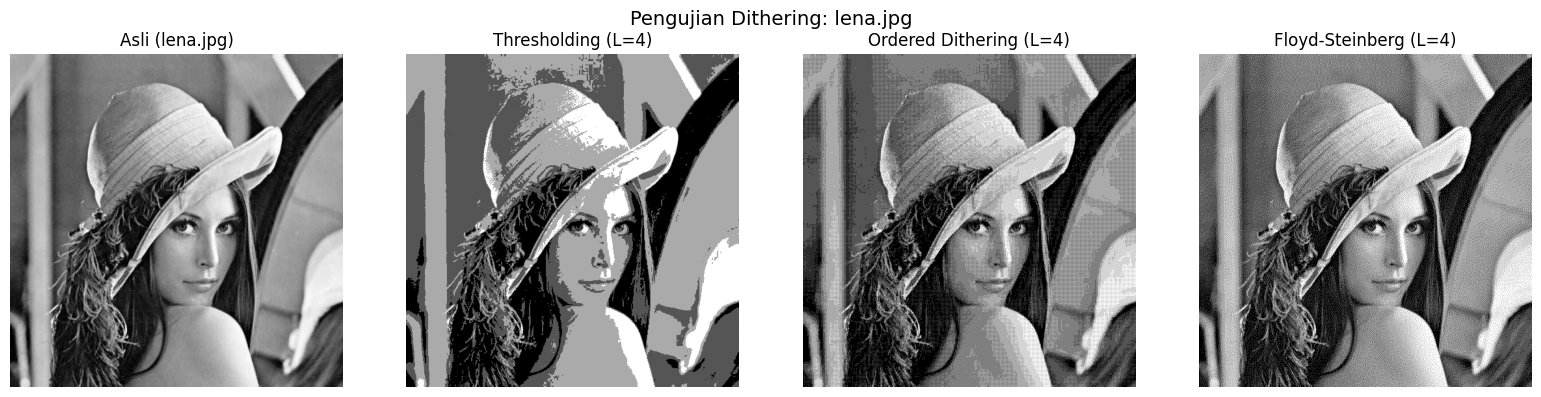

Error: Gambar pada '/content/drive/MyDrive/PCVK/Images/KTM1b.jpg' tidak ditemukan!


In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

def simple_thresholding(gray, L=2):
    """Kuantisasi sederhana tanpa dithering"""
    step = 255.0 / (L - 1)
    return (np.round(gray / step) * step).astype(np.uint8)

def ordered_dithering(gray, L=2):
    """Ordered Dithering menggunakan Matriks Bayer 2x2"""
    bayer_matrix = np.array([
        [0, 2],
        [3, 1]
    ]) / 4.0

    img = gray.astype(np.float32) / 255.0
    H, W = img.shape
    dithered = np.zeros_like(img)

    step = 1.0 / (L - 1)
    for y in range(H):
        for x in range(W):
            thresh = bayer_matrix[y % 2, x % 2] * step
            val = img[y, x] + thresh - (step / 2.0)
            quantized = np.round(val / step) * step
            dithered[y, x] = np.clip(quantized, 0.0, 1.0)

    return (dithered * 255).astype(np.uint8)

def floyd_steinberg(gray, L=2):
    """Error Diffusion Dithering (Floyd-Steinberg Algorithm)"""
    img = gray.astype(np.float32).copy()
    step = 255.0 / (L - 1)
    H, W = img.shape

    for y in range(H):
        for x in range(W):
            lama = img[y, x]
            baru = np.round(lama / step) * step  # warna palet terdekat
            img[y, x] = baru
            error = lama - baru

            if x + 1 < W:
                img[y, x + 1] += error * 7 / 16
            if x > 0 and y + 1 < H:
                img[y + 1, x - 1] += error * 3 / 16
            if y + 1 < H:
                img[y + 1, x] += error * 5 / 16
            if x + 1 < W and y + 1 < H:
                img[y + 1, x + 1] += error * 1 / 16

    return np.clip(img, 0, 255).astype(np.uint8)


# 1. PERCOBAAN DITHERING UTAMA (E-3 No. 1)

L_val = PARAM.get('L', 2 ** ((int(NIM[-3:]) % 3) + 1))

# Tahap 1 & 2: Pengujian Citra Contoh dan Citra KTM
berkas_uji = [
    (CONTOH + '/lena.jpg', "lena.jpg"),
    (BASE + '/KTM1b.jpg', "KTM1b.jpg")
]

for path, nama in berkas_uji:
    gray_img = cv.imread(path, cv.IMREAD_GRAYSCALE)
    if gray_img is None:
        print(f"Error: Gambar pada '{path}' tidak ditemukan!")
        continue

    res_thresh = simple_thresholding(gray_img, L=L_val)
    res_ordered = ordered_dithering(gray_img, L=L_val)
    res_floyd = floyd_steinberg(gray_img, L=L_val)

    fig, axes = plt.subplots(1, 4, figsize=(16, 4))

    axes[0].imshow(gray_img, cmap='gray')
    axes[0].set_title(f"{NIM} - Asli ({nama})", fontsize=10)
    axes[0].axis('off')

    axes[1].imshow(res_thresh, cmap='gray')
    axes[1].set_title(f"Thresholding (L={L_val})", fontsize=10)
    axes[1].axis('off')

    axes[2].imshow(res_ordered, cmap='gray')
    axes[2].set_title(f"Ordered Dithering (L={L_val})", fontsize=10)
    axes[2].axis('off')

    axes[3].imshow(res_floyd, cmap='gray')
    axes[3].set_title(f"Floyd-Steinberg (L={L_val})", fontsize=10)
    axes[3].axis('off')

    plt.suptitle(f"{NIM} - Pengujian Dithering: {nama}", fontsize=13)
    plt.tight_layout()
    plt.show()

berkas_eq_dither = [
    (CONTOH + '/lena_lc.jpg', "lena_lc.jpg"),
    (BASE + '/KTM1a.jpg', "KTM1a.jpg")
]

for path, nama in berkas_eq_dither:
    gray_img = cv.imread(path, cv.IMREAD_GRAYSCALE)
    if gray_img is None:
        continue

    # Urutan A: Dithering Langsung
    dither_direct = floyd_steinberg(gray_img, L=L_val)

    # Urutan B: Ekualisasi Dulu -> Dithering
    eq_img = cv.equalizeHist(gray_img)
    dither_after_eq = floyd_steinberg(eq_img, L=L_val)

    fig, axes = plt.subplots(1, 4, figsize=(16, 4))

    axes[0].imshow(gray_img, cmap='gray')
    axes[0].set_title(f"{NIM} - Asli ({nama})", fontsize=10)
    axes[0].axis('off')

    axes[1].imshow(eq_img, cmap='gray')
    axes[1].set_title("Hasil Ekualisasi", fontsize=10)
    axes[1].axis('off')

    axes[2].imshow(dither_direct, cmap='gray')
    axes[2].set_title(f"Dithering Langsung (L={L_val})", fontsize=10)
    axes[2].axis('off')

    axes[3].imshow(dither_after_eq, cmap='gray')
    axes[3].set_title(f"Ekualisasi -> Dithering (L={L_val})", fontsize=10)
    axes[3].axis('off')

    plt.suptitle(f"{NIM} - Perbandingan Urutan Process: {nama}", fontsize=13)
    plt.tight_layout()
    plt.show()